In [2]:
from qiskit import QuantumCircuit
from qiskit.synthesis.qft import synth_qft_full
from qiskit import quantum_info as qi
from qiskit.visualization import array_to_latex
from qiskit_aer import Aer

In [3]:
qc = QuantumCircuit(1)
qc.initialize('1', qc.qubits)
qc.compose(synth_qft_full(1), qubits=qc.qubits, inplace=True)

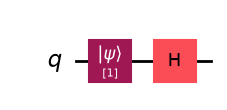

In [4]:
qc.draw("mpl")

In [5]:
psi_f = qi.Statevector.from_circuit(qc)
array_to_latex(psi_f, prefix=r"\Psi_f = ")

<IPython.core.display.Latex object>

**QFT**

_1 qubit_

$$
\ket{0} \to \frac{1}{\sqrt{2}}(\ket{0} + \ket{1}) \equiv \ket{+} = \frac{1}{\sqrt{2}} \left(e^{2\pi i (0*0)/2} \ket{0} + e^{2\pi i (0*1)/2}\right)
$$

$$
\ket{1} \to \frac{1}{\sqrt{2}}(\ket{0} - \ket{1}) \equiv \ket{-} = \frac{1}{\sqrt{2}} \left(e^{2\pi i (1*0)/2} + e^{2\pi i (1*1)/2}\right)

In [6]:
qc = QuantumCircuit(2)
qc.initialize('10', qc.qubits)
qc.compose(synth_qft_full(2), qubits=qc.qubits, inplace=True)

qc.draw("mpl")
psi_f = qi.Statevector.from_circuit(qc)
array_to_latex(psi_f, prefix=r"\Psi_f = ")

<IPython.core.display.Latex object>

_2 qubits_
$$
\ket{00} \to \frac{1}{2}(\ket{00} + \ket{10} + \ket{10} + \ket{11})
$$
$$
\ket{01} \to \frac{1}{2}(\ket{00} + i\ket{10} - \ket{10} - i\ket{11})
$$
$$
\ket{10} \to \frac{1}{2}(\ket{00} - \ket{10} + \ket{10} - \ket{11})
$$
$$
\ket{11} \to \frac{1}{2}(\ket{00} - i\ket{10} - \ket{10} +i\ket{11})
$$

In [7]:
# Another way of running
backend = Aer.get_backend('statevector_simulator')
psi_f = backend.run(qc).result().get_statevector()
array_to_latex(psi_f, prefix=r"\Psi_f = ")

<IPython.core.display.Latex object>

In [8]:
qc = QuantumCircuit(5)
qc.initialize('00000', qc.qubits)
qc.compose(synth_qft_full(5), qubits=qc.qubits, inplace=True)

qc.draw()

┌────────────────────────┐                                              »
q_0: ┤0                       ├──────────────────────────────────────────────»
     │                        │                                              »
q_1: ┤1                       ├─────────────────────────────■────────────────»
     │                        │                             │                »
q_2: ┤2 Initialize(0,0,0,0,0) ├───────────────■─────────────┼────────■───────»
     │                        │               │       ┌───┐ │        │P(π/2) »
q_3: ┤3                       ├──────■────────┼───────┤ H ├─┼────────■───────»
     │                        │┌───┐ │P(π/2)  │P(π/4) └───┘ │P(π/8)          »
q_4: ┤4                       ├┤ H ├─■────────■─────────────■────────────────»
     └────────────────────────┘└───┘                                         »
«                                                                      ┌───┐   
«q_0: ─■───────────────────────■─────────────────■─────────────■───────┤ H ├─X─
«      │                       │                 │       ┌───┐ │P(π/2) └───┘ │ 
«q_1: ─┼─────────■─────────────┼────────■────────┼───────┤ H ├─■─────────X───┼─
«      │         │       ┌───┐ │        │P(π/2)  │P(π/4) └───┘           │   │ 
«q_2: ─┼─────────┼───────┤ H ├─┼────────■────────■───────────────────────┼───┼─
«      │         │P(π/4) └───┘ │P(π/8)                                   │   │ 
«q_3: ─┼─────────■─────────────■─────────────────────────────────────────X───┼─
«      │P(π/16)                                                              │ 
«q_4: ─■─────────────────────────────────────────────────────────────────────X─
«

In [9]:
psi_f = qi.Statevector.from_circuit(qc)
array_to_latex(psi_f, prefix=r"\Psi_f = ")

<IPython.core.display.Latex object>

**Afternoon Session**

In [11]:
from qiskit import QuantumRegister

In [15]:
qr = QuantumRegister(1)
qc = QuantumCircuit(qr)
qc.initialize('+', qr)
qc.h(qr)
psi_f = qi.Statevector.from_circuit(qc)
array_to_latex(psi_f, prefix=r"\Psi_f = ")

<IPython.core.display.Latex object>

In [16]:
qr = QuantumRegister(2)
qc = QuantumCircuit(qr)
qc.initialize('++', qr)
qc.h(qr)
psi_f = qi.Statevector.from_circuit(qc)
array_to_latex(psi_f, prefix=r"\Psi_f = ")

<IPython.core.display.Latex object>

Problem: Board Picture

![alt text](QMC.jpeg)

In [22]:
import numpy as np
import matplotlib.pyplot as plt

In [18]:
def make_discretized_positions(xmin, xmax, N):
    x = np.linspace(xmin, xmax, N)
    return x

In [19]:
num_qubits = 6
N = 2**num_qubits
xmin = -2*np.pi
xmax = 2**np.pi
x = make_discretized_positions(xmin, xmax, N)

In [29]:
def gaussian_wavefunction(x, mu, sigma, p0):
    wave = (1/np.sqrt(2*np.pi*sigma**2))*np.exp(-((x-mu)**2)/(2*sigma**2) + 1.0j*p0*(x-mu))
    return wave

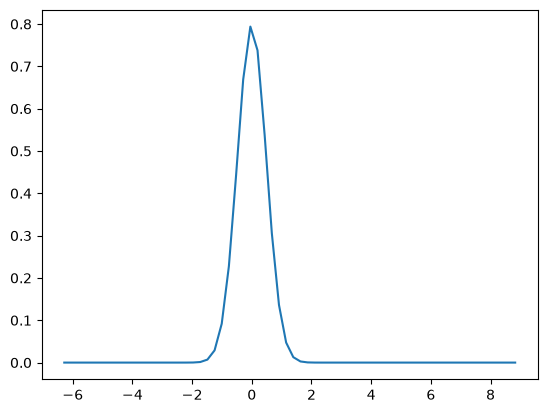

In [32]:
mu = 0.0
sigma = 0.5
p0 = 0.5

wave = gaussian_wavefunction(x, mu, sigma, p0)
plt.plot(x, np.real(wave))
plt.show()